In [48]:
 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [49]:
DATA_DIR = Path("../data/raw")
csv_files = list(DATA_DIR.glob("*.csv"))

if not csv_files:
    raise FileNotFoundError(
        f"No csv file found inside {DATA_DIR}"
    )

In [50]:
DATA_PATH = csv_files[0]
df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully")

Dataset loaded successfully


In [51]:
df.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [52]:
df.tail()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
1995,STU1996,23,Male,2,7.5,20.3,1.89,7.3,10.7,High,8.2,6.3,80.9,No,Average,No,Medium
1996,STU1997,21,Male,2,6.4,16.8,2.14,4.6,5.8,Moderate,4.6,3.5,76.9,Yes,Poor,No,High
1997,STU1998,19,Female,1,4.5,13.1,2.54,7.5,10.0,Low,6.7,8.1,87.9,Yes,NaN,No,High
1998,STU1999,21,Male,3,8.1,22.3,2.62,4.5,6.6,Moderate,6.5,8.4,100.0,No,Good,No,Low
1999,STU2000,19,Female,3,5.9,23.3,2.56,7.6,11.2,High,7.7,8.9,87.6,No,Average,No,Medium


In [53]:
df.shape

(2000, 17)

In [67]:
df.columns.tolist()

['Student_ID',
 'Age',
 'Gender',
 'Year_of_Study',
 'Sleep_Hours',
 'Study_Hours_Per_Week',
 'GPA',
 'Social_Media_Hours',
 'Screen_Time_Hours',
 'Physical_Activity',
 'Financial_Stress',
 'Family_Support',
 'Attendance_Rate',
 'Part_Time_Job',
 'Diet_Quality',
 'Previous_Mental_Health_History',
 'Mental_Health_Risk']

In [55]:
df.dtypes

Student_ID                            str
Age                                 int64
Gender                                str
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                     str
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                         str
Diet_Quality                          str
Previous_Mental_Health_History        str
Mental_Health_Risk                    str
dtype: object

In [56]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

In [57]:
numerical_features = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()
print(numerical_features)

['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']


In [71]:
categorical_features = df.select_dtypes(
    include=["str", "category", "bool"]
).columns.tolist()

categorical_features = [
    col for col in categorical_features
    if col not in ["Student_ID", "Mental_Health_Risk"]
]
print(categorical_features)

['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']


In [59]:
df.isnull().sum()

Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64

In [60]:
duplicated = df.duplicated().sum()
print(duplicated)

0


In [61]:
df.Gender.unique()

<ArrowStringArray>
['Male', 'Female', 'Non-binary']
Length: 3, dtype: str

In [62]:
unique_values = pd.DataFrame({
    "Feature": df.columns,
    "Unique_count": [
        df[col].nunique() for col in df.columns
    ]
})

unique_values.sort_values(
    by="Unique_count",
    ascending=True
)

,Feature,Unique_count
13,Part_Time_Job,2
15,Previous_Mental_Health_History,2
2,Gender,3
9,Physical_Activity,3
14,Diet_Quality,3
16,Mental_Health_Risk,3
3,Year_of_Study,5
1,Age,13
4,Sleep_Hours,66
7,Social_Media_Hours,71


In [63]:
df.describe()

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


In [64]:
df.describe(include="object")

/tmp/ipykernel_37131/702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Student_ID,Gender,Physical_Activity,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
count,2000,2000,2000,2000,1931,2000,2000
unique,2000,3,3,2,3,2,3
top,STU0001,Female,Moderate,No,Average,No,High
freq,1,971,906,1289,860,1408,680


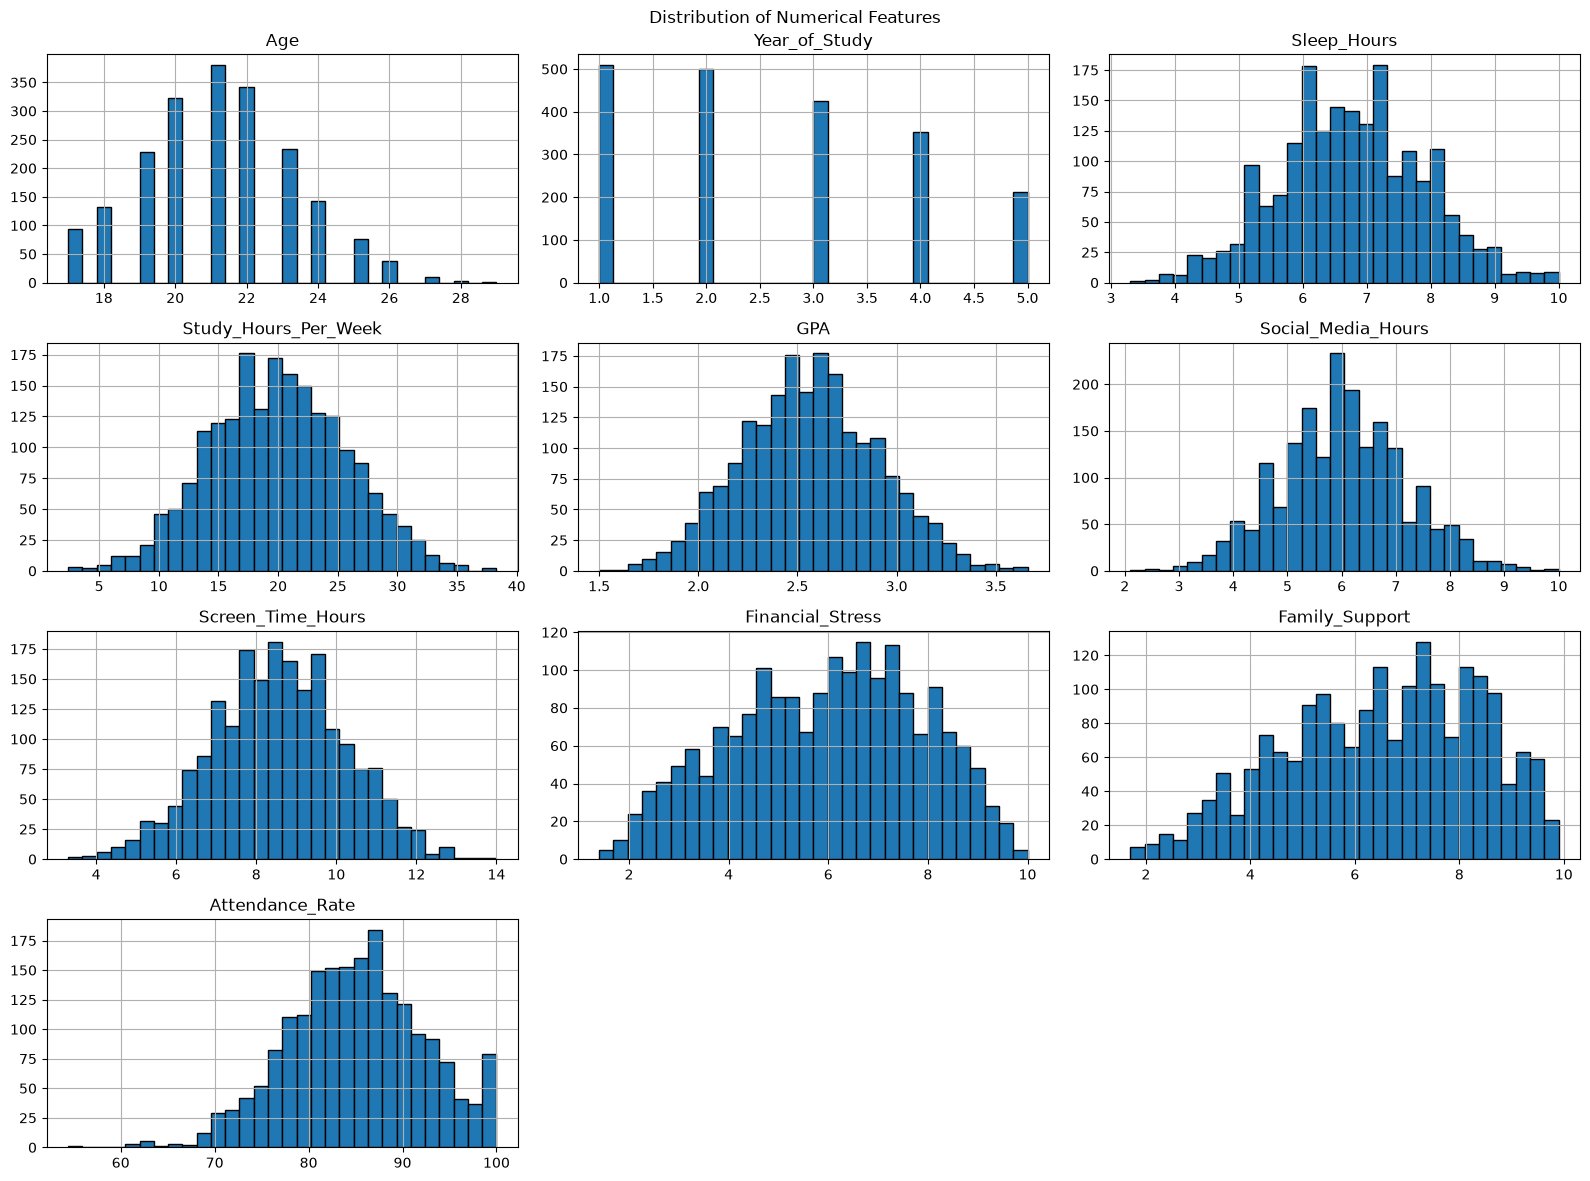

In [65]:
df[numerical_features].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

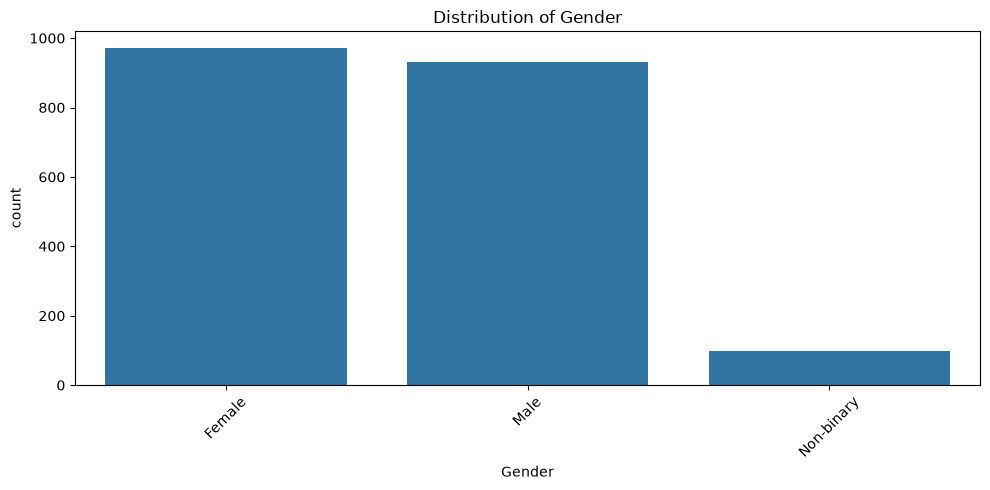

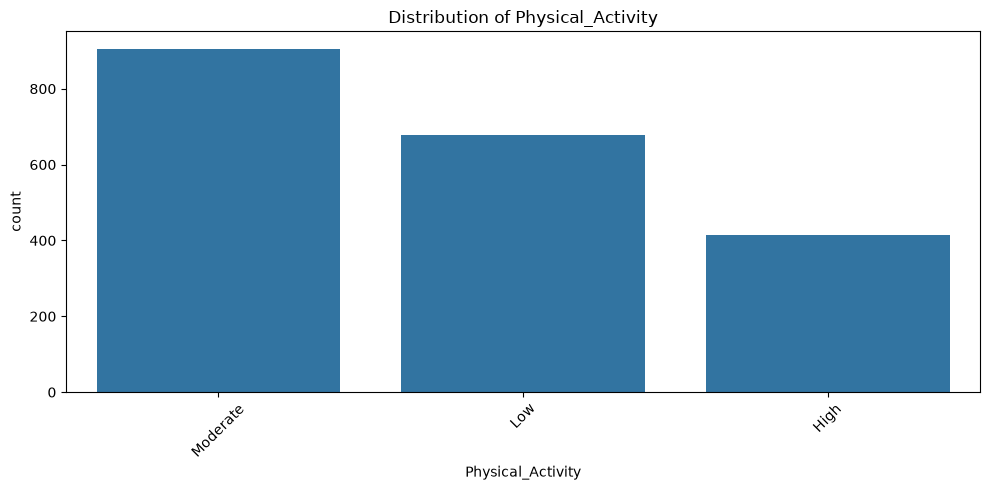

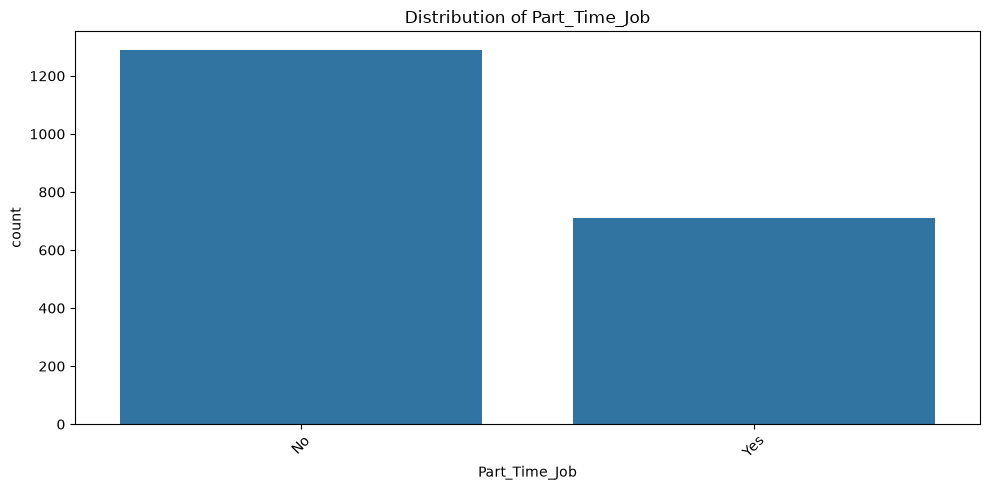

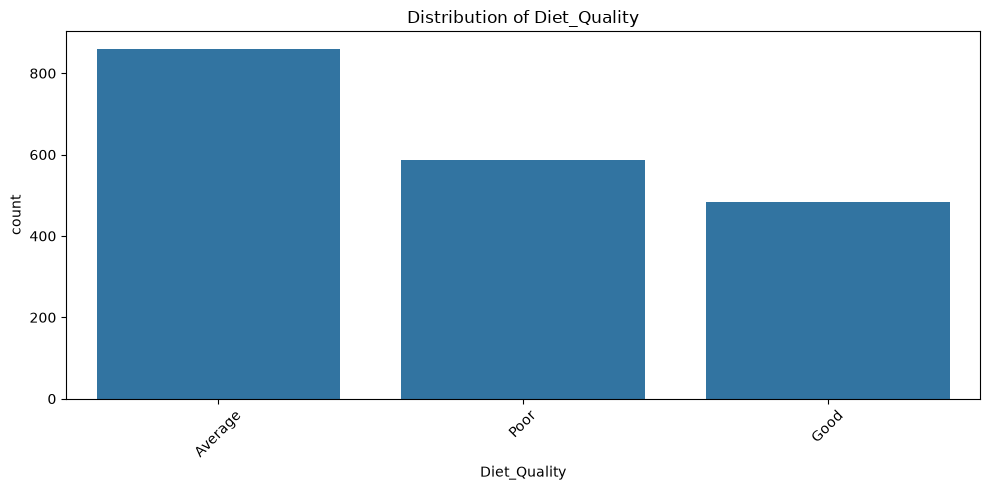

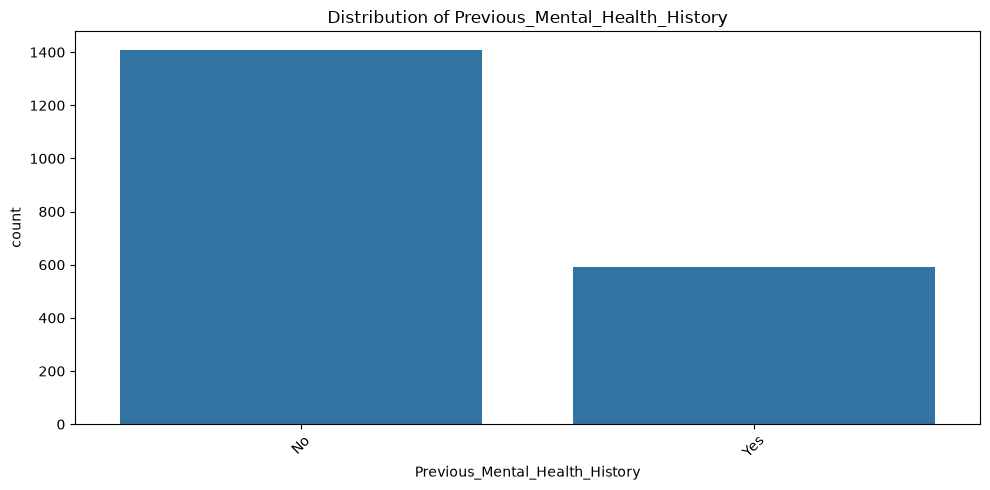

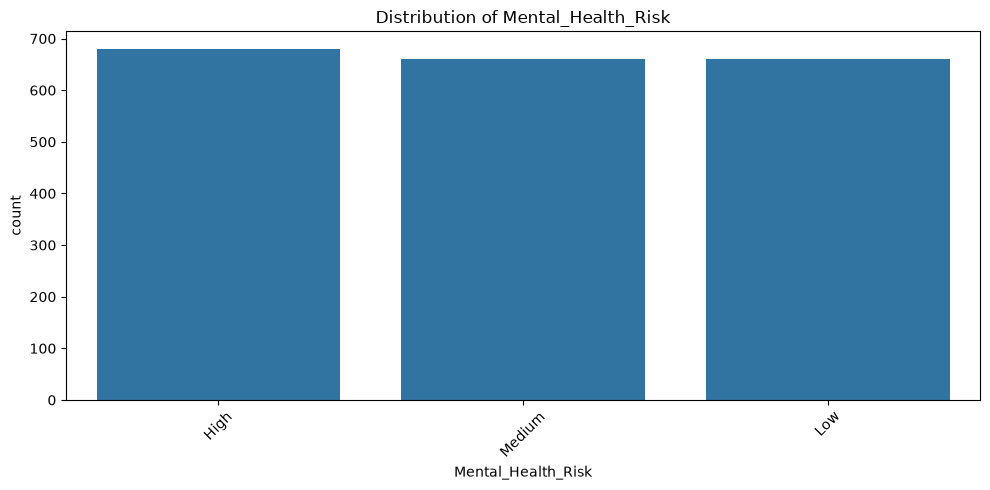

In [66]:
for column in categorical_features:
    plt.figure(figsize=(10, 5))

    order = df[column].value_counts().index

    sns.countplot(
        data=df,
        x=column,
        order=order
    )

    plt.title(f"Distribution of {column}")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [68]:
df["Mental_Health_Risk"].unique()

<ArrowStringArray>
['High', 'Medium', 'Low']
Length: 3, dtype: str

In [69]:
target_percentages = (
    df["Mental_Health_Risk"].value_counts(normalize=True) * 100
)
print(target_percentages.round(2))

Mental_Health_Risk
High      34.0
Medium    33.0
Low       33.0
Name: proportion, dtype: float64


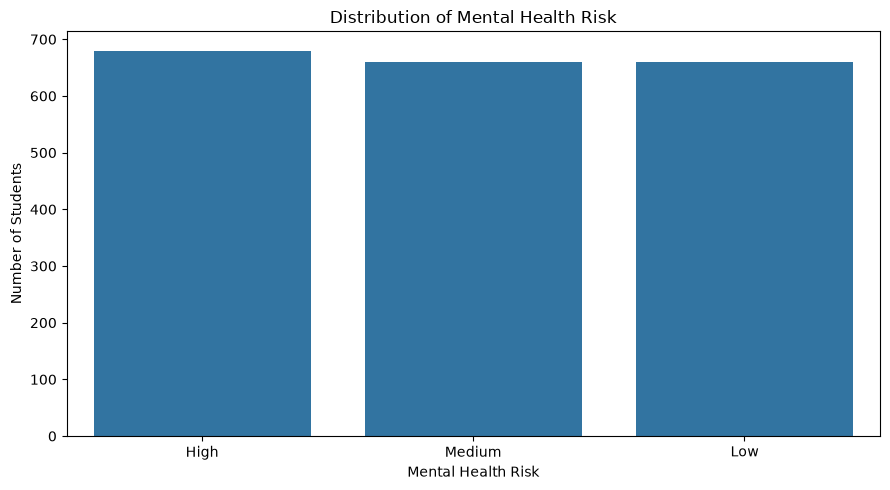

In [70]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Mental_Health_Risk",
    order=df["Mental_Health_Risk"].value_counts().index
)

plt.title("Distribution of Mental Health Risk")
plt.xlabel("Mental Health Risk")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

In [ ]:
target = "Mental_Health_Risk"

X = df.drop(columns=["Student_ID", target])
y = df[target]

In [74]:
outlier_results = []

for col in numerical_features:

    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = X[
        (X[col] < lower_bound) |
        (X[col] > upper_bound)
    ][col]

    outlier_results.append({
        "Feature": col,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": (
            len(outliers) / len(X) * 100
        )
    })

outlier_df = pd.DataFrame(outlier_results)

outlier_df

,Feature,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,Age,15.5000,27.5000,4,0.20
1,Year_of_Study,-3.5000,8.5000,0,0.00
2,Sleep_Hours,3.6000,10.0000,2,0.10
3,Study_Hours_Per_Week,4.0000,36.0000,7,0.35
4,GPA,1.6150,3.4950,9,0.45
5,Social_Media_Hours,3.0125,8.9125,20,1.00
6,Screen_Time_Hours,3.9500,13.1500,7,0.35
7,Financial_Stress,0.1500,11.7500,0,0.00
8,Family_Support,0.7500,12.3500,0,0.00
9,Attendance_Rate,65.7500,104.5500,12,0.60
